# TAHAP 5 - EKSTRAKSI FITUR BENTUK (BKPM Acara 22-23)

Setiap objek pada label (gambar asli + varian) dirasterisasi menjadi citra biner, lalu:

`bwlabeln 8-tetangga -> area -> perimeter -> bentuk -> circularity -> kode rantai`

| Fitur | Arti |
|---|---|
| `luas_px` | jumlah piksel objek (area) |
| `keliling_batas_px` | jumlah piksel batas objek (rumus source code Acara 23) |
| `keliling_rantai_px` | panjang kode rantai: tegak/mendatar = 1, diagonal = akar 2 (Acara 22) |
| `bentuk` | keliling² / luas (faktor bentuk) |
| `circularity` | 4·π·luas / keliling² (1 = lingkaran) |
| `luas_rel`, `rasio_tw`, `extent`, `solidity`, `eksentrisitas` | geometri tambahan |

Fitur dipakai sebagai **kontrol kualitas**: objek dengan luas < 100 px atau `luas_rel` < 0,3% ditandai `terlalu_kecil` dan **dibuang oleh tahap 6** (gambar tanpa objek tersisa ikut dibuang).

**Keluaran** `hasil/05_fitur_bentuk/`: `fitur_bentuk.csv`, `ringkasan_per_kelas.csv`, `kode_rantai.csv`, `kamus_fitur.csv`.

Letakkan notebook ini di `notebooks/`; modul pendukung ada di `scripts/`.

## 1. Setup dan import

In [1]:
import sys, os
from pathlib import Path

SCRIPTS = Path.cwd().resolve().parent / "scripts"
if not SCRIPTS.is_dir():
    SCRIPTS = Path.cwd().resolve()
sys.path.insert(0, str(SCRIPTS))

# Opsional: bila folder proyek bukan induk dari scripts/, hilangkan tanda # dan isi path-nya
# os.environ["PROYEK_ROOT"] = r"D:\rompi-cerdas-fin"

import math
from collections import defaultdict

import cv2
import numpy as np
from IPython.display import Image, display

import bkpm
from config import CLASSES, D_AUG, D_FITUR, ROOT
from util import baca_csv, bersihkan, log, tabel, tulis_csv
from yolo_util import baca_label_seg

TAHAP = "05_fitur_bentuk"
print("Folder proyek :", ROOT)
print("Input manifest:", D_AUG / "manifest_pengayaan.csv", "| ada:", (D_AUG / "manifest_pengayaan.csv").exists())
print("Folder hasil  :", D_FITUR)

Folder proyek : C:\Projek\vestcare-dataset
Input manifest: C:\Projek\vestcare-dataset\hasil\04_pengayaan\manifest_pengayaan.csv | ada: True
Folder hasil  : C:\Projek\vestcare-dataset\hasil\05_fitur_bentuk


## 2. Konstanta dan kamus fitur

Ambang kontrol kualitas (`terlalu_kecil`) sama dengan skrip asli: luas < 100 px atau `luas_rel` < 0,003.

In [2]:
MIN_LUAS_PX = 100
MIN_LUAS_REL = 0.003

FITUR = ["luas_px", "keliling_batas_px", "keliling_rantai_px", "bentuk", "circularity", "luas_rel",
         "bbox_lebar", "bbox_tinggi", "rasio_tw", "extent", "solidity", "eksentrisitas"]
KOLOM = ["file", "sumber", "varian", "kelas", "id_objek"] + FITUR + ["qc"]
KAMUS = {
    "luas_px": "area: jumlah piksel objek", "keliling_batas_px": "perimeter: jumlah piksel batas (Acara 23)",
    "keliling_rantai_px": "perimeter dari kode rantai (Acara 22)", "bentuk": "keliling_batas^2 / luas",
    "circularity": "4*pi*luas/keliling_batas^2 (1 = lingkaran)", "luas_rel": "luas objek / luas gambar",
    "bbox_lebar": "lebar kotak pembatas", "bbox_tinggi": "tinggi kotak pembatas", "rasio_tw": "tinggi / lebar kotak",
    "extent": "luas / luas kotak pembatas", "solidity": "luas / luas convex hull",
    "eksentrisitas": "0 = bulat, mendekati 1 = memanjang (dari momen citra)",
    "qc": "terlalu_kecil (luas < 100 px atau luas_rel < 0,003) / ok",
}
tabel("Kamus fitur", [{"fitur": k, "arti": v} for k, v in KAMUS.items()], ["fitur", "arti"])


Kamus fitur
fitur               arti                                                    
luas_px             area: jumlah piksel objek                               
keliling_batas_px   perimeter: jumlah piksel batas (Acara 23)               
keliling_rantai_px  perimeter dari kode rantai (Acara 22)                   
bentuk              keliling_batas^2 / luas                                 
circularity         4*pi*luas/keliling_batas^2 (1 = lingkaran)              
luas_rel            luas objek / luas gambar                                
bbox_lebar          lebar kotak pembatas                                    
bbox_tinggi         tinggi kotak pembatas                                   
rasio_tw            tinggi / lebar kotak                                    
extent              luas / luas kotak pembatas                              
solidity            luas / luas convex hull                                 
eksentrisitas       0 = bulat, mendekati 1 = memanjang (dari mo

## 3. Fungsi ekstraksi dan fungsi bantu

`fitur_objek(m, h, w)` menerima mask biner satu objek dan mengembalikan fitur serta kode rantai. `mask_dari_label` merasterisasi polygon label.

In [3]:
def fitur_objek(m, h, w):
    a = int(m.sum())
    per = bkpm.perimeter_batas(m)
    rantai = bkpm.kode_rantai(m)
    ys, xs = np.nonzero(m)
    bw, bh = int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1)
    hull = cv2.contourArea(cv2.convexHull(np.stack([xs, ys], 1).astype(np.int32)))
    mu = cv2.moments(m.astype(np.uint8), binaryImage=True)
    d = math.sqrt(max(0.0, ((mu["mu20"] - mu["mu02"]) / 2) ** 2 + mu["mu11"] ** 2))
    l1, l2 = (mu["mu20"] + mu["mu02"]) / 2 + d, (mu["mu20"] + mu["mu02"]) / 2 - d
    ecc = math.sqrt(max(0.0, 1 - l2 / l1)) if l1 > 0 else 0.0
    f = {"luas_px": a, "keliling_batas_px": per, "keliling_rantai_px": round(bkpm.keliling_rantai(rantai), 2),
         "bentuk": round(bkpm.faktor_bentuk(a, per), 3), "circularity": round(bkpm.circularity(a, per), 4),
         "luas_rel": round(a / (h * w), 5), "bbox_lebar": bw, "bbox_tinggi": bh, "rasio_tw": round(bh / bw, 3),
         "extent": round(a / (bw * bh), 4), "solidity": round(a / hull, 4) if hull > 0 else "",
         "eksentrisitas": round(ecc, 4)}
    f["qc"] = "terlalu_kecil" if (a < MIN_LUAS_PX or a / (h * w) < MIN_LUAS_REL) else "ok"
    return f, rantai


def mask_dari_label(rel, h, w):
    """Rasterisasi polygon relatif -> mask biner; ambil komponen terbesar (8-tetangga). None bila kosong."""
    m = np.zeros((h, w), np.uint8)
    cv2.fillPoly(m, [np.round(rel * [w, h]).astype(np.int32)], 1)
    n, lab, st = bkpm.bwlabeln(m, 8)
    if n == 0:
        return None
    return lab == (1 + int(np.argmax(st[:, 4])))


def tampil(img, maks=1100):
    h, w = img.shape[:2]
    s = min(1.0, maks / max(h, w))
    if s < 1.0:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    display(Image(data=cv2.imencode(".png", img)[1].tobytes()))


def tampil_baris(daftar, tinggi=190, per_baris=4):
    """daftar = [(citra BGR, teks)]"""
    for i in range(0, len(daftar), per_baris):
        ubin = []
        for im, teks in daftar[i:i + per_baris]:
            s = tinggi / im.shape[0]
            t = cv2.resize(im, (max(1, int(im.shape[1] * s)), tinggi), interpolation=cv2.INTER_AREA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 0, 0), 3, cv2.LINE_AA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            ubin.append(t)
        tampil(np.hstack(ubin))

print("fungsi siap")

fungsi siap


## 4. Baca manifest pengayaan

In [4]:
man = baca_csv(D_AUG / "manifest_pengayaan.csv")
if not man:
    raise SystemExit("manifest_pengayaan.csv kosong: jalankan notebook 04_pengayaan dulu")
print("Gambar di manifest:", len(man))
tabel("Gambar per kelas", [{"kelas": k, "gambar": sum(r["kelas"] == k for r in man)} for k in CLASSES], ["kelas", "gambar"])

Gambar di manifest: 2944

Gambar per kelas
kelas   gambar
pohon   561   
lubang  634   
orang   492   
motor   660   
mobil   597   


## 5. Demo langkah demi langkah pada satu objek

Urutan: polygon label -> rasterisasi -> **bwlabeln 8-tetangga** -> **area** -> **perimeter (piksel batas)** -> **kode rantai** -> **faktor bentuk** -> **circularity**. Panel: **mask objek | piksel batas | gambar + kotak pembatas + convex hull**.

File : pohon_primer-pohon-1.jpg | kelas pohon | varian asli | objek di label: 1
1. rasterisasi polygon          : piksel objek = 65720
2. bwlabeln 8-tetangga          : komponen = 1 | luas tiap komponen = [65720]
3. area (komponen terbesar)     : 65720 piksel
4. perimeter (piksel batas)     : 1389
5. kode rantai                  : panjang 1389 | 20 kode pertama: 55565555555655545454
6. keliling dari kode rantai    : 1555.93
7. bentuk = keliling^2 / luas   : 29.357
8. circularity = 4*pi*A/P^2     : 0.4281

Semua fitur: {'luas_px': 65720, 'keliling_batas_px': 1389, 'keliling_rantai_px': 1555.93, 'bentuk': 29.357, 'circularity': 0.4281, 'luas_rel': 0.50635, 'bbox_lebar': 205, 'bbox_tinggi': 416, 'rasio_tw': 2.029, 'extent': 0.7706, 'solidity': 0.8314, 'eksentrisitas': 0.8691, 'qc': 'ok'}


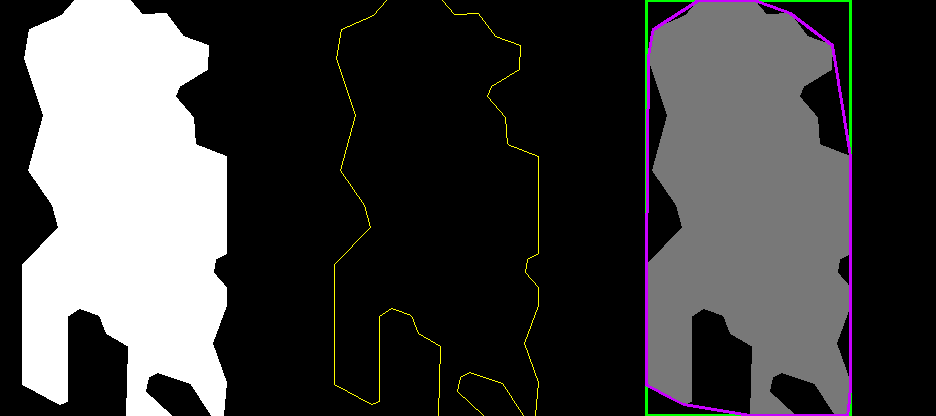

In [5]:
r0 = man[0]
stem0 = r0["file"].rsplit(".", 1)[0]
h, w = int(r0["tinggi"]), int(r0["lebar"])
label0 = baca_label_seg(D_AUG / "labels_seg" / f"{stem0}.txt")
print("File :", r0["file"], f"| kelas {r0['kelas']} | varian {r0['varian']} | objek di label: {len(label0)}")

kid, rel = label0[0]
m_kasar = np.zeros((h, w), np.uint8)
cv2.fillPoly(m_kasar, [np.round(rel * [w, h]).astype(np.int32)], 1)
print("1. rasterisasi polygon          : piksel objek =", int(m_kasar.sum()))
n, lab, st = bkpm.bwlabeln(m_kasar, 8)
print("2. bwlabeln 8-tetangga          : komponen =", n, "| luas tiap komponen =", st[:, 4].tolist())
m = mask_dari_label(rel, h, w)
a = int(m.sum())
print("3. area (komponen terbesar)     :", a, "piksel")
per = bkpm.perimeter_batas(m)
print("4. perimeter (piksel batas)     :", per)
rantai = bkpm.kode_rantai(m)
print("5. kode rantai                  : panjang", len(rantai), "| 20 kode pertama:", "".join(map(str, rantai[:20])))
print("6. keliling dari kode rantai    :", round(bkpm.keliling_rantai(rantai), 2))
print("7. bentuk = keliling^2 / luas   :", round(bkpm.faktor_bentuk(a, per), 3))
print("8. circularity = 4*pi*A/P^2     :", round(bkpm.circularity(a, per), 4))

f0, _ = fitur_objek(m, h, w)
print("\nSemua fitur:", f0)

# visualisasi
mu8 = m.astype(np.uint8)
dalam = cv2.erode(mu8, np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], np.uint8))
batas = (mu8 & (1 - dalam)).astype(np.uint8)
v1 = cv2.cvtColor(mu8 * 255, cv2.COLOR_GRAY2BGR)
v2 = np.zeros((h, w, 3), np.uint8)
v2[batas > 0] = (0, 255, 255)
v3 = cv2.cvtColor(mu8 * 120, cv2.COLOR_GRAY2BGR)
ys, xs = np.nonzero(m)
cv2.rectangle(v3, (int(xs.min()), int(ys.min())), (int(xs.max()), int(ys.max())), (0, 255, 0), 2)
hull = cv2.convexHull(np.stack([xs, ys], 1).astype(np.int32))
cv2.polylines(v3, [hull], True, (255, 0, 200), 2)
tampil(np.hstack([v1, v2, v3]))

## 6. Ekstraksi fitur seluruh objek

> Sel ini **menghapus dan membuat ulang** `hasil/05_fitur_bentuk/`.

In [6]:
bersihkan(D_FITUR)
baris, rantai_csv = [], []
for r in man:
    stem = r["file"].rsplit(".", 1)[0]
    h, w = int(r["tinggi"]), int(r["lebar"])
    for idx, (kid, rel) in enumerate(baca_label_seg(D_AUG / "labels_seg" / f"{stem}.txt")):
        m = mask_dari_label(rel, h, w)               # komponen terbesar = objek
        if m is None:
            continue
        f, rantai = fitur_objek(m, h, w)
        baris.append({"file": r["file"], "sumber": r["sumber"], "varian": r["varian"], "kelas": CLASSES[kid],
                      "id_objek": idx, **f})
        rantai_csv.append({"file": r["file"], "id_objek": idx, "panjang_kode": len(rantai),
                           "kode_rantai": "".join(map(str, rantai))})
print("Objek diproses:", len(baris))
print("Objek ditandai terlalu_kecil:", sum(b["qc"] != "ok" for b in baris))

Objek diproses: 3854
Objek ditandai terlalu_kecil: 14


## 7. Simpan CSV

In [7]:
tulis_csv(D_FITUR / "fitur_bentuk.csv", baris, KOLOM)
tulis_csv(D_FITUR / "kode_rantai.csv", rantai_csv, ["file", "id_objek", "panjang_kode", "kode_rantai"])
tulis_csv(D_FITUR / "kamus_fitur.csv", [{"fitur": k, "arti": v} for k, v in KAMUS.items()], ["fitur", "arti"])
for p in ("fitur_bentuk.csv", "kode_rantai.csv", "kamus_fitur.csv"):
    print(f"{p:20s} {(D_FITUR / p).stat().st_size / 1024:9.1f} KB")

fitur_bentuk.csv         528.2 KB
kode_rantai.csv         3966.2 KB
kamus_fitur.csv            0.6 KB


## 8. Ringkasan fitur per kelas (objek `qc = ok`)

Rata-rata dan simpangan baku tiap fitur per kelas. Dari sini terlihat ciri bentuk tiap kelas: orang tinggi (`rasio_tw` besar), mobil lebar (`rasio_tw` kecil), dan seterusnya.

In [8]:
ring = []
for k in CLASSES:
    x = [b for b in baris if b["kelas"] == k and b["qc"] == "ok"]
    if not x:
        continue
    row = {"kelas": k, "n_objek": len(x)}
    for f in ("luas_rel", "rasio_tw", "circularity", "bentuk", "solidity", "eksentrisitas"):
        v = np.array([float(b[f]) for b in x if b[f] != ""])
        row[f + "_rata"], row[f + "_sd"] = round(float(v.mean()), 3), round(float(v.std()), 3)
    ring.append(row)
kol = list(ring[0].keys()) if ring else ["kelas"]
tulis_csv(D_FITUR / "ringkasan_per_kelas.csv", ring, kol)
tabel("Ringkasan fitur bentuk (objek qc=ok)", ring, ["kelas", "n_objek", "luas_rel_rata", "rasio_tw_rata", "circularity_rata",
                                                     "bentuk_rata", "solidity_rata", "eksentrisitas_rata"])
log(TAHAP, f"{len(baris)} objek, {sum(b['qc'] != 'ok' for b in baris)} ditandai terlalu_kecil -> {D_FITUR}")


Ringkasan fitur bentuk (objek qc=ok)
kelas   n_objek  luas_rel_rata  rasio_tw_rata  circularity_rata  bentuk_rata  solidity_rata  eksentrisitas_rata
pohon   561      0.457          0.997          0.682             19.478       0.876          0.638             
lubang  1053     0.123          0.557          0.372             42.988       0.775          0.872             
orang   691      0.156          2.2            0.441             31.21        0.791          0.861             
motor   872      0.29           0.716          0.516             31.057       0.788          0.81              
mobil   663      0.262          0.689          0.582             24.065       0.857          0.788             
[05_fitur_bentuk] 3854 objek, 14 ditandai terlalu_kecil -> C:\Projek\vestcare-dataset\hasil\05_fitur_bentuk


## 9. Kontrol kualitas: objek `terlalu_kecil`

Objek yang akan dibuang tahap 6, per kelas dan per varian. Bila banyak yang terbuang di satu varian (mis. `crop`), pertimbangkan menyetel pengayaan.

In [9]:
print(f"{'kelas':8s} {'objek':>6s} {'ok':>6s} {'terlalu_kecil':>14s} {'% buang':>8s}")
for k in CLASSES:
    rr = [b for b in baris if b["kelas"] == k]
    if rr:
        kecil = sum(b["qc"] != "ok" for b in rr)
        print(f"{k:8s} {len(rr):6d} {len(rr) - kecil:6d} {kecil:14d} {100 * kecil / len(rr):8.1f}")

varians = sorted({b["varian"] for b in baris})
print(f"\n{'varian':10s} {'objek':>6s} {'terlalu_kecil':>14s}")
for v in varians:
    rr = [b for b in baris if b["varian"] == v]
    print(f"{v:10s} {len(rr):6d} {sum(b['qc'] != 'ok' for b in rr):14d}")

kecil = sorted([b for b in baris if b["qc"] != "ok"], key=lambda b: float(b["luas_px"]))[:8]
if kecil:
    print("\nContoh objek terkecil:")
    for b in kecil:
        print(f"  {b['file'][:40]:40s} luas={b['luas_px']} luas_rel={b['luas_rel']}")

kelas     objek     ok  terlalu_kecil  % buang
pohon       561    561              0      0.0
lubang     1067   1053             14      1.3
orang       691    691              0      0.0
motor       872    872              0      0.0
mobil       663    663              0      0.0

varian      objek  terlalu_kecil
asli         1408              7
cerah         314              3
crop          285              0
flip_h        317              0
gaussian      311              0
gelap         310              0
gerak         299              1
histeq        296              3
kontras       314              0

Contoh objek terkecil:
  lubang_288.jpg                           luas=190 luas_rel=0.00211
  lubang_288__histeq.jpg                   luas=190 luas_rel=0.00211
  lubang_193.jpg                           luas=208 luas_rel=0.00278
  lubang_193__cerah.jpg                    luas=208 luas_rel=0.00278
  lubang_288.jpg                           luas=213 luas_rel=0.00237
  lubang_288__hist

## 10. Galeri objek per kelas

Mask beberapa objek per kelas dengan nilai circularity, rasio tinggi/lebar, dan solidity. Ditampilkan objek dari foto asli saja.


== pohon: 187 objek asli, tampil 6 ==


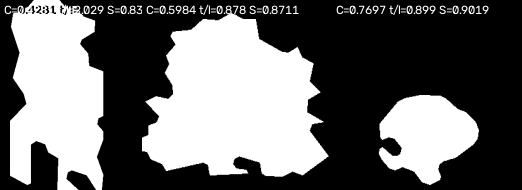

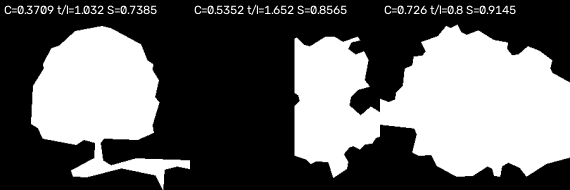


== lubang: 529 objek asli, tampil 6 ==


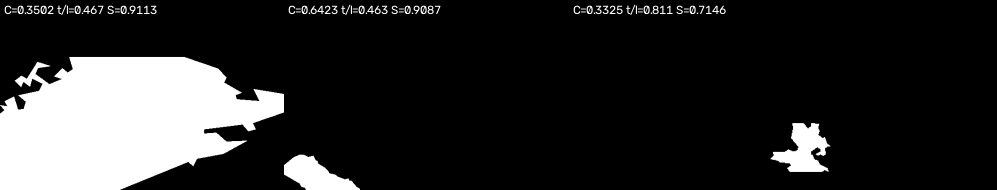

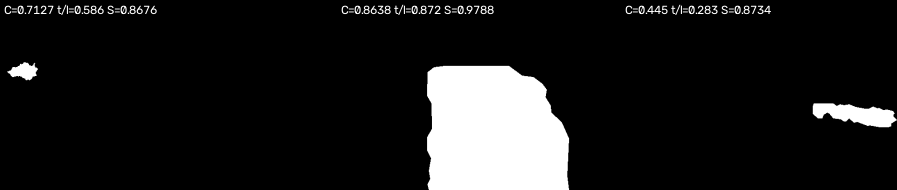


== orang: 173 objek asli, tampil 6 ==


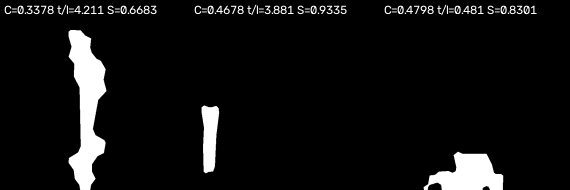

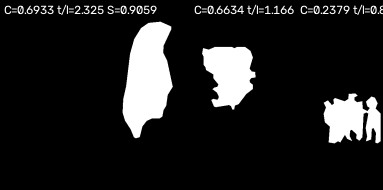


== motor: 291 objek asli, tampil 6 ==


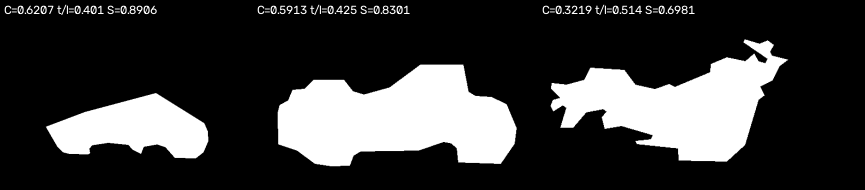

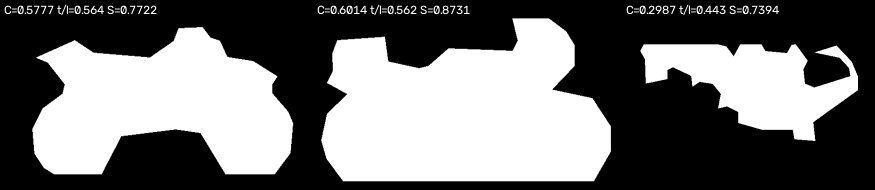


== mobil: 221 objek asli, tampil 6 ==


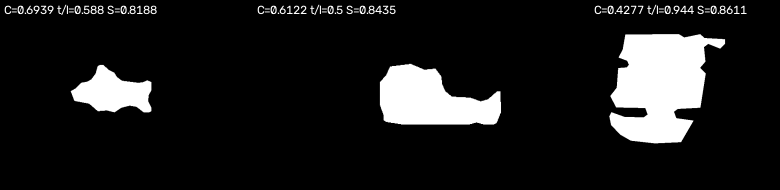

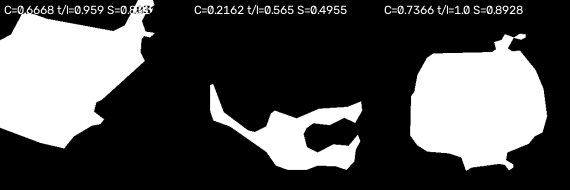

In [10]:
MAKS_GALERI = 6
for k in CLASSES:
    rr = [b for b in baris if b["kelas"] == k and b["varian"] == "asli" and b["qc"] == "ok"]
    if not rr:
        continue
    pilih = rr[::max(1, len(rr) // MAKS_GALERI)][:MAKS_GALERI]
    print(f"\n== {k}: {len(rr)} objek asli, tampil {len(pilih)} ==")
    galeri = []
    for b in pilih:
        stem = b["file"].rsplit(".", 1)[0]
        mrow = next(x for x in man if x["file"] == b["file"])
        hh, ww = int(mrow["tinggi"]), int(mrow["lebar"])
        _, rel = baca_label_seg(D_AUG / "labels_seg" / f"{stem}.txt")[int(b["id_objek"])]
        mk = mask_dari_label(rel, hh, ww)
        im = cv2.cvtColor(mk.astype(np.uint8) * 255, cv2.COLOR_GRAY2BGR)
        galeri.append((im, f"C={b['circularity']} t/l={b['rasio_tw']} S={b['solidity']}"))
    tampil_baris(galeri, tinggi=190, per_baris=3)

## 11. Sebaran fitur per kelas

Persentil 10, 50, dan 90 untuk fitur utama. Rentang antar kelas yang berbeda menunjukkan fitur itu cukup membedakan kelas.

In [11]:
for f in ("luas_rel", "rasio_tw", "circularity", "solidity"):
    print(f"\n{f}")
    print(f"  {'kelas':8s} {'p10':>8s} {'median':>8s} {'p90':>8s}")
    for k in CLASSES:
        v = np.array([float(b[f]) for b in baris if b["kelas"] == k and b["qc"] == "ok" and b[f] != ""])
        if len(v):
            print(f"  {k:8s} {np.percentile(v, 10):8.3f} {np.median(v):8.3f} {np.percentile(v, 90):8.3f}")


luas_rel
  kelas         p10   median      p90
  pohon       0.257    0.462    0.654
  lubang      0.008    0.053    0.343
  orang       0.027    0.109    0.346
  motor       0.050    0.267    0.567
  mobil       0.055    0.215    0.523

rasio_tw
  kelas         p10   median      p90
  pohon       0.676    0.899    1.346
  lubang      0.259    0.505    0.908
  orang       1.166    1.972    3.623
  motor       0.459    0.591    1.068
  mobil       0.398    0.658    0.960

circularity
  kelas         p10   median      p90
  pohon       0.484    0.697    0.848
  lubang      0.173    0.340    0.626
  orang       0.282    0.438    0.586
  motor       0.224    0.528    0.702
  mobil       0.344    0.586    0.812

solidity
  kelas         p10   median      p90
  pohon       0.827    0.872    0.939
  lubang      0.597    0.793    0.913
  orang       0.668    0.801    0.920
  motor       0.611    0.812    0.921
  mobil       0.752    0.862    0.972


## 12. Pemeriksaan akhir

In [12]:
ada = {p.name: p.exists() for p in (D_FITUR / "fitur_bentuk.csv", D_FITUR / "ringkasan_per_kelas.csv",
                                    D_FITUR / "kode_rantai.csv", D_FITUR / "kamus_fitur.csv")}
print("Berkas keluaran:", ada)
ok = sum(b["qc"] == "ok" for b in baris)
print(f"Objek total={len(baris)}  ok={ok}  terlalu_kecil={len(baris) - ok}")
log(TAHAP, f"selesai -> {D_FITUR}")
print("\nLanjut ke notebook 06_dataset_yolo26.ipynb")

Berkas keluaran: {'fitur_bentuk.csv': True, 'ringkasan_per_kelas.csv': True, 'kode_rantai.csv': True, 'kamus_fitur.csv': True}
Objek total=3854  ok=3840  terlalu_kecil=14
[05_fitur_bentuk] selesai -> C:\Projek\vestcare-dataset\hasil\05_fitur_bentuk

Lanjut ke notebook 06_dataset_yolo26.ipynb
